
# Landing Page A/B Testing & Conversion Analysis

**Python | Pandas | Statistical Hypothesis Testing | Data Visualisation**

## Project Overview

This project evaluates the performance of two landing-page variants using an A/B testing dataset provided as part of the TripleTen Data Analytics Bootcamp.

The objective is to determine whether Version B demonstrates improved conversion performance compared with Version A, while examining customer spending and potential differences across user segments.

## Business Questions

1. Which landing-page version achieves the higher conversion rate?
2. Is the observed difference in conversion statistically significant?
3. Does average spending among converted users differ between variants?
4. Are conversion outcomes associated with traffic source or user type?
5. What commercial decision is supported by the experiment results?

## Analytical Approach

The analysis uses Python to explore the dataset, calculate conversion metrics, visualise performance differences, and apply statistical hypothesis tests.

Findings are interpreted in terms of statistical evidence, business relevance, and limitations.

---

## Analysis & Python Implementation


In [5]:
# importar librerías
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
from scipy.stats import levene
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chi2_contingency


In [6]:
# cargar archivo

from pathlib import Path

data_path = Path("landing_experiment.csv")
if not data_path.exists():
    data_path = Path("landing_experiment") / "landing_experiment.csv"

df = pd.read_csv(data_path)


**Vista previa e información general del conjunto de datos**

In [7]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [8]:
# información general
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  str    
 1   date            40000 non-null  str    
 2   landing         40000 non-null  str    
 3   region          40000 non-null  str    
 4   dispositivo     40000 non-null  str    
 5   traffic_source  40000 non-null  str    
 6   user_type       40000 non-null  str    
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), str(7)
memory usage: 1.7 MB


✍️ **Comentario**: El dataset no tiene valores ausentes.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [9]:
df['user_id'].nunique()

40000

 **Variable `date`**  
Explorar rango de fechas

In [10]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [11]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [12]:
# Resumen estadístico
df['gasto'].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [13]:
# Resumen estadístico de usuarios que se convirtieron
(df[df['converted'] == 1]['gasto']).describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [14]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
print(df['landing'].value_counts())

print("\nConteo de categorías:")
print(df['traffic_source'].value_counts())

print("\nConteo de categorías:")
print(df['user_type'].value_counts())

print("\nConteo de categorías:")
print(df['region'].value_counts())

print("\nConteo de categorías:")
print(df['dispositivo'].value_counts())


Conteo de categorías:
landing
B    20018
A    19982
Name: count, dtype: int64

Conteo de categorías:
traffic_source
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: count, dtype: int64

Conteo de categorías:
user_type
Nuevo         26033
Recurrente    13967
Name: count, dtype: int64

Conteo de categorías:
region
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: count, dtype: int64

Conteo de categorías:
dispositivo
Mobile     24829
Desktop    15171
Name: count, dtype: int64


✍️ **Comentario**: Todas las columnas tienen valores esperados.

## 💰 Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [15]:
# Gasto por versión

gasto_A = df[(df['landing']=='A')&(df['converted']==1)]
gasto_B = df[(df['landing']=='B')&(df['converted']==1)]

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [16]:
# Gasto promedio de todos los usuarios
df.groupby('landing')['gasto'].mean()
print(df.groupby('landing')['gasto'].mean())
print()
# Gasto promedio de los usuarios convertidos
gasto_convertidos_A = df[(df['landing']=='A')&(df['converted']==1)]['gasto'].mean()
print(f'Gasto promedio de usuarios convertidos en A:{gasto_convertidos_A:.3f}')

gasto_convertidos_B = df[(df['landing']=='B')&(df['converted']==1)]['gasto'].mean()
print(f'Gasto promedio de usuarios convertidos en B:{gasto_convertidos_B:.3f}')

landing
A     7.679385
B    10.968762
Name: gasto, dtype: float64

Gasto promedio de usuarios convertidos en A:61.087
Gasto promedio de usuarios convertidos en B:68.745


In [17]:
# Aplicar Levene
gasto_A_levene= df[(df['landing']=='A')&(df['converted']==1)]['gasto']
gasto_B_levene= df[(df['landing']=='B')&(df['converted']==1)]['gasto']

l_stat,p_value_var= levene(gasto_A_levene, gasto_B_levene)
print(f'Estadístico de Levene:{l_stat}')
print(f'valor p: {p_value_var}')

alpha= 0.05
if p_value_var < alpha:
    print('Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False)')
else:
    print('No rechazamos la hipótesis nula: no hay evidencia de varianzas diferentes (equal_var=True)')

Estadístico de Levene:29.17646453202917
valor p: 6.875301988006785e-08
Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False)


### Prueba T_test

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio del grupo A y el del grupo B es el mismo.
- **Hipótesis alternativa (H₁):** El gasto promedio del grupo A es diferente al gasto promedio del grupo B.

In [18]:
# Aplicar prueba
t_stat,p_value= st.ttest_ind(gasto_A_levene,gasto_B_levene,equal_var=False)

# Visualizar resultados
print(f"Estadístico : {t_stat}")
print(f"Valor p: {p_value}")

Estadístico : -9.48101092267275
Valor p: 3.627602231521494e-21


In [19]:
alpha=0.05
if p_value < alpha:
    print('Rechazamos la hipótesis nula, hay evidencia de promedios diferentes.')
else:
    print('No rechazamos la hipótesis nula, no hay evidencia de promedios diferentes.')


Rechazamos la hipótesis nula, hay evidencia de promedios diferentes.


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula. 

**Interpretación de negocio:**  
Existe una diferencia clara entre los gastos promedio del grupo A y los del grupo B. Evaluando el promedio de gasto de los usuarios convertidos se obtuvo: 
`A = $61.09
B = $68.75` que se confirma estadísticamente con el `valor P:3.63e-21` y el rechazo de la hipótesis nula de la prueba T. Bajo estos números se recomienda cambiar e implementar la página B.


## 📈 Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z-Test

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión es la misma entre A y B.
- **Hipótesis alternativa (H₁):** La tasa de conversión difiere entre A y B.

In [20]:
# Número de usuarios convertidos por página
conversiones= df.groupby('landing')['converted'].sum()

# Total de usuarios por página
totales= df['landing'].value_counts()

print("Usuarios convertidos por página:\n",df.groupby('landing')['converted'].sum())
print("\nTotal de usuarios por página:\n",df['landing'].value_counts())

# Exitos y Observaciones 
exitos= [conversiones['A'],conversiones['B']]
observaciones= [totales['A'],totales['B']]


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
B    20018
A    19982
Name: count, dtype: int64


In [21]:
# Aplicar prueba
z_stat, p_value = proportions_ztest(exitos,observaciones)

# Visualizar resultados
print(f'Estadístico Z: {z_stat:.3f}')
print(f'Valor P: {p_value:.3f}')

alpha=0.05
if p_value < alpha:
    print('Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables')
else:
    print('No rechazamos la hipótesis nula:no hay evidencia suficiente de asociación entre las variables')

#tasas de conversión por página
tasa_A= conversiones['A']/totales['A']
tasa_B= conversiones['B']/totales['B']
print(f'tasa de conversion pagina A: {tasa_A:.3f}')
print(f'tasa de conversion pagina B: {tasa_B:.3f}')

Estadístico Z: -9.677
Valor P: 0.000
Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables
tasa de conversion pagina A: 0.126
tasa de conversion pagina B: 0.160


### 📝 Conclusión e interpretación

**Decisión:**  Se rechaza la hipótesis nula.

**Interpretación de negocio:**  
Con base en los resultados de `Estadístico Z` -9.67 y `valor de P` 0.000, la tasa de conversión entre la página A (12.6%) y la página B (16.0%) muestra diferencias que se confirman con el rechazo de la hipótesis nula. La conversión es más alta el B, lo que coincide con la interpretación de la prueba T del promedio de gasto por página. Se recomienda implementar la página B. 

## 7.0🔗 Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba Chi2

**Hipótesis:**
- **Hipótesis nula (H₀):** No hay una asociación estadísticamente significativa entre la `fuente de tráfico` y la `conversión`.
- **Hipótesis alternativa (H₁):** Hay una asociación estadísticamente significativa entre la `fuente de tráfico` y la `conversión`. 

In [22]:
# Número de conversiones por cada fuente de tráfico
conversiones_trafico= df.groupby('traffic_source')['converted'].sum()

# Total de visitantes para cada fuente de tráfico
totales_trafico= df['traffic_source'].value_counts()

print("Número de conversiones por fuente de tráfico:\n",df.groupby('traffic_source')['converted'].sum())
print("\nTotal de visitantes para cada fuente de tráfico:\n",df['traffic_source'].value_counts())

Número de conversiones por fuente de tráfico:
 traffic_source
Ads         1759
Email        918
Organic     2480
Referral     549
Name: converted, dtype: int64

Total de visitantes para cada fuente de tráfico:
 traffic_source
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: count, dtype: int64


In [23]:
# Aplicar prueba
tabla= pd.crosstab(df['traffic_source'],df['converted']) 
chi2_stat,p_value,dof,expected= chi2_contingency(tabla)
# Visualizar datos
print(f"Estadístico chi_cuadrado: {chi2_stat:.3f}") 
print(f"Valor p: {p_value:.3f}")

alpha=0.05 
if p_value < alpha: 
    print('Rechazamos la hipótesis nula: hay evidencia de asociación estadísticamente significativa entre las variables') 
else: 
    print('No rechazamos la hipótesis nula:no hay evidencia suficiente de asociación estadísticamente significativa entre las variables')

Estadístico chi_cuadrado: 8.662
Valor p: 0.034
Rechazamos la hipótesis nula: hay evidencia de asociación estadísticamente significativa entre las variables


In [24]:

#tasas de conversión por página
tasa_email= conversiones_trafico['Email']/totales_trafico['Email']
tasa_organic= conversiones_trafico['Organic']/totales_trafico['Organic']
tasa_referral= conversiones_trafico['Referral']/totales_trafico['Referral']
tasa_ads= conversiones_trafico['Ads']/totales_trafico['Ads']

print(f'tasa de conversión por email: {tasa_email:.3f}')
print(f'tasa de conversión por organic: {tasa_organic:.3f}')
print(f'tasa de conversión por referral: {tasa_referral:.3f}')
print(f'tasa de conversión por ads: {tasa_ads:.3f}')



tasa de conversión por email: 0.150
tasa de conversión por organic: 0.138
tasa de conversión por referral: 0.139
tasa de conversión por ads: 0.147


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula.

**Interpretación de negocio:**  
De acuerdo con las cifras absolutas de conversión por `fuente de tráfico` tenemos que las fuentes con menor porcentaje de conversión son las que generan màs conversión de usuarios, por ejemplo `organic` tiene una tasa de conversión de 13.8% siendo la màs baja, sin embargo convirtió a 2480 usuarios de 17987 que visitaron la pàgina por ese medio, mientras que `email` es la tasa de conversión màs alta pero solo convirtio 918 usuarios de 6123. Esto significa que hay que revisar los números antes de tomar una decisión, sobre qué fuente genera más conversión, considerando que el data set tiene 40 mil entradas.


## 👤 8. Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi2

**Hipótesis:**
- **Hipótesis nula (H₀):** No hay evidencia estadísticamante significativa de asociación entre `tipo de usuario` y `conversion`.
- **Hipótesis alternativa (H₁):** Hay evidencia estadísticamente significativa de asociación entre `tipo de usuario` y `conversion`.

In [25]:
# Número de conversiones por tipo de usuario
conversiones_tipo_usuario= df.groupby('user_type')['converted'].sum()

# Total de tipos de usuarios 
totales_tipo_usuario= df['user_type'].value_counts()

print("Número de conversiones por tipo de usuario:\n",df.groupby('user_type')['converted'].sum())
print("\nTotal de tipos de usuario:\n",df['user_type'].value_counts())

Número de conversiones por tipo de usuario:
 user_type
Nuevo         3738
Recurrente    1968
Name: converted, dtype: int64

Total de tipos de usuario:
 user_type
Nuevo         26033
Recurrente    13967
Name: count, dtype: int64


In [26]:
# Aplicar prueba
tabla= pd.crosstab(df['user_type'],df['converted'])
chi2_stat,p_value,dof,expected= chi2_contingency(tabla)

# Visualizar resultados
print(f"Estadístico chi_cuadrado: {chi2_stat:.3f}")
print(f"Valor p: {p_value:.3f}")

alpha=0.05
if p_value < alpha:
    print('Rechazamos la hipótesis nula: hay evidencia de asociación estadísticamente significativa entre las variables')
else:
    print('No rechazamos la hipótesis nula:no hay evidencia suficiente de asociación estadísticamente significativa entre las variables')

Estadístico chi_cuadrado: 0.513
Valor p: 0.474
No rechazamos la hipótesis nula:no hay evidencia suficiente de asociación estadísticamente significativa entre las variables


In [27]:
#tasas de conversión por tipo de usuario
tasa_nuevo= conversiones_tipo_usuario['Nuevo']/totales_tipo_usuario['Nuevo']
tasa_recurrente= conversiones_tipo_usuario['Recurrente']/totales_tipo_usuario['Recurrente']

print(f'tasa de conversión usuario nuevo: {tasa_nuevo:.3f}')
print(f'tasa de conversión usuario recurrente: {tasa_recurrente:.3f}')

tasa de conversión usuario nuevo: 0.144
tasa de conversión usuario recurrente: 0.141


### 📝 Conclusión e interpretación

**Decisión:**  No se rechaza la hipótesis nula.

**Interpretación de negocio:**  
Con los resultados obtenidos del análisis `p_value` 0.474 y `chi_cuadrado` 0.513, se demuestra que no hay evidencia estadistica significante de asociación entre las variables, lo cual se confirma con las tasas de conversión por tipo de usuarios que son muy similares (nuevo= 14.4% y recurrente=14.1%)que podría no es una diferencia no real pero puede ser producto del azar, esto significa que el tipo de usuario no influye en la conversión que generan. 

## 📊 9. Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

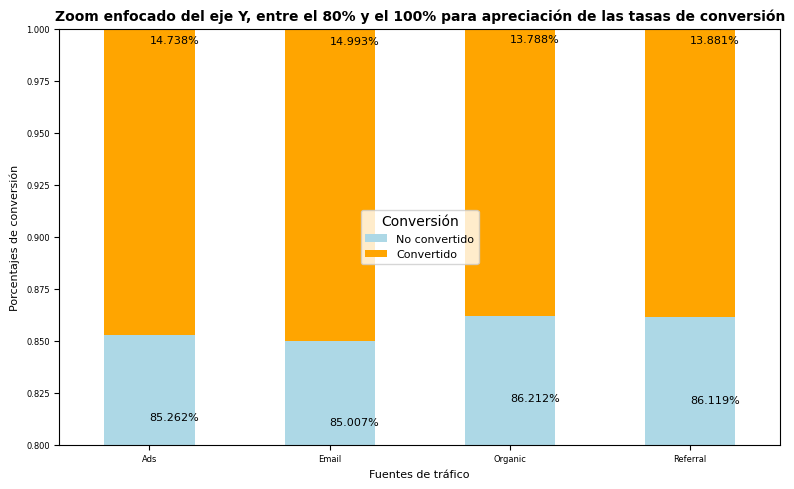

In [28]:
# Gráfico de conversión por fuente de tráfico 
tabla= pd.crosstab(df['traffic_source'],df['converted'],normalize='index')
ax= tabla.plot(kind='bar',stacked=True,figsize=(8,5),color=['lightblue','orange'])
for container in ax.containers:
    for rect in container:
        x_centro = rect.get_x() + rect.get_width() / 2
        y_centro = rect.get_y() + rect.get_height() / 1.05
        plt.text(x_centro,y_centro,f'{(rect.get_height())*100:.3f}%',fontsize=8)
plt.title('Zoom enfocado del eje Y, entre el 80% y el 100% para apreciación de las tasas de conversión',fontsize=10,fontweight='bold')
plt.xlabel('Fuentes de tráfico',fontsize=8)
plt.ylabel('Porcentajes de conversión', fontsize=8)
plt.ylim(0.8,1)
plt.xticks(rotation=0,fontsize=6)
plt.yticks(fontsize=6)
plt.legend(title='Conversión',labels=['No convertido','Convertido'],loc='center',fontsize=8)
plt.tight_layout()
plt.show()

✍️ **Comentario**: El gráfico es un resumen de las tasas de conversión por fuente de tráfico; se presenta en formato Zoom para identificar las variaciones  mínimas en los porcentajes de conversión por fuente de tráfico del negocio. Las tasas de conversión por fuente de tráfico son:
-Ads: 14.7%
-Email: 15%
-Organic: 13.8%
-Referral: 13.9%
Como se analizó en la prueba de `chi_cuadrado` 8.662 y `valor de P` 0.034, se rechazó la hipótesis nula, y el gráfico confirma que sí hay diferencias estadísticas entre las variables, estos resultados no son definidos por el azar.

### Relación entre el tipo de usuario y la conversión

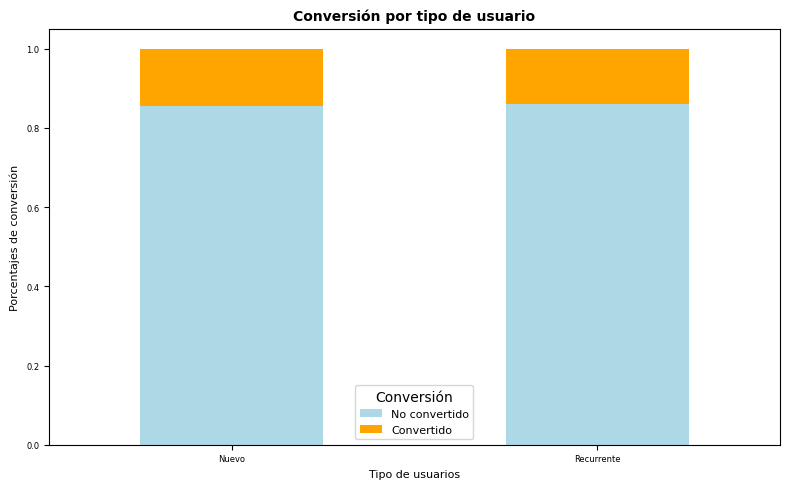

In [29]:
# Gráfico de conversión por tipo de usuario 
tabla= pd.crosstab(df['user_type'],df['converted'],normalize='index')
ax= tabla.plot(kind='bar',stacked=True,figsize=(8,5),color=['lightblue','orange'])
plt.title('Conversión por tipo de usuario',fontsize=10,fontweight='bold')
plt.xlabel('Tipo de usuarios',fontsize=8)
plt.ylabel('Porcentajes de conversión',fontsize=8)
plt.xticks(rotation=0,fontsize=6)
plt.yticks(fontsize=6)
plt.legend(title='Conversión',labels=['No convertido','Convertido'],fontsize=8)
plt.tight_layout()
plt.show()

✍️ **Comentario**: Este gráfico muestra los porcentajes de conversión por tipo de usuario, las dos barras son practicamente iguales debido a las tasas de conversion obtenidas, donde `conversión por usuario nuevo` es de 14.4% y `conversión por usuario recurrente` es de 14.1%, y confirma el análisis aplicado de `chi cuadrado` 0.513 y el `valor de P`0.474. Al no rechazarse la hipoteisis nula, y tener evidencia de asociacion entre las variables, se confirma que el tipo de usuario no influye en la conversión.


## 🧩 10. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- El gasto promedio de usuarios convertidos es mayor en la página B (68.75) y tiene un total de usuarios  convertidos de 3194, mientras que el gasto promedio de usuarios convertidos en A (61.09) es menor y tiene un total de usuarios convertidos de 2512.La relación entre las variables presenta un valor `estadístico T de -9.48`y un `valor P de 3.63e-21`. La hipótesis nula fue rechazada ya que sí hay diferencias estadísticas en el promedio de gasto de los usuarios entre las diferentes páginas.
- **Interpretación:**
Se confirma estadísticamente que las diferencias en el gasto promedio de los usuarios por página no son fruto del azar y sí repercuten en el ingreso generado para el negocio.

**Tasa de conversión:** 
- tasa de conversión página A: 0.126
- tasa de conversión página B: 0.160
- La prueba `Estadístico Z = -9.67`y el  `p-valor = 0.000` muestran diferencias estadísticamente significativas.
**Interpretación:**
  La Página B logró una tasa de conversión del 16.0% frente al 12.6% de la Página A (un incremento de +3.4 puntos porcentuales). Además, los usuarios que se convirtieron en B gastaron un promedio de $68.75 comparado con los $61.09 de A.

#### 📊 **Segmentación por fuente de tráfico**
- La prueba de asociación confirma que el canal de origen influye significativamente en la probabilidad de conversión `valor P = 0.034`
**Interpretación:**
- Tráfico Orgánico: Representa el mayor volumen absoluto de conversiones (2,480 usuarios), aunque su tasa relativa es del 13.8%.
- Email y Ads: Muestran la mayor tasa de conversión efectiva (15.0% y 14.7% respectivamente), siendo los canales más eficientes por impacto directo por visitante.
Es decir, mientras que el canal orgánico sostiene el volumen de ventas por escala de tráfico, email y ads son los motores con mejor rendimiento.

#### 📊 **Segmentación por tipo de usuario**
- Las tasas de conversión son prácticamente idénticas (14.4% para nuevos y 14.1% para recurrentes).Se conserva la hipótesis nula `valor P = 0.474`. No existen diferencias estadísticamente significativas entre ambos grupos.
**Interpretación:**
El tipo de usuario no determina la propensión a la compra. El rediseño de la landing funciona con la misma eficacia tanto para usuarios nuevos como para aquellos que regresan a la plataforma.

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

#### 💡 **Recomendaciones de negocio:** 
- Despliegue total de la Página B: Reemplazar de forma definitiva la versión A para maximizar inmediatamente la tasa de conversión global y el ticket promedio.
- Reasignación de presupuesto publicitario: Incrementar la inversión en Email Marketing y campañas de Ads por su alta tasa de retorno por visitante, aprovechando que la nueva landing B optimiza esa adquisición.
- Enfoque unificado de UX: Mantener una experiencia de usuario estandarizada en la landing page sin necesidad de crear caminos segmentados rígidos para usuarios nuevos vs. recurrentes, dado que responden con la misma efectividad.